# Vegetables Classification using DCNN
Klasifikasi 4 sayur (Broccoli, Carrot, Cucumber, Tomato) dengan Deep Convolutional Neural Network.

Alur: **Load & Split → Preprocessing → Model → Training → Predict & Evaluate → Plot**

In [1]:
# Import Library
import os
import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Load Dataset

In [2]:
PATH = "dataset/"

# Nama kelas = nama folder. isdir() + sorted() -> abaikan file seperti .DS_Store & urutan label selalu sama
CLASS_NAMES = sorted(c for c in os.listdir(PATH) if os.path.isdir(PATH + c))
print("Classes:", CLASS_NAMES)

Classes: ['Broccoli', 'Carrot', 'Cucumber', 'Tomato']


## Load Image
`x` = gambar, `y` = label (index kelas: Broccoli = 0, Carrot = 1, Cucumber = 2, Tomato = 3)

Soal minta grayscale (1 channel). Kalau mau RGB: ganti `color_mode="rgb"` dan semua channel `1` jadi `3` (di `Input` model).

In [3]:
rows, cols = 224, 224

x, y = [], []

counter = 0  # index kelas

for class_name in CLASS_NAMES:
    for img_name in os.listdir(PATH + class_name):
        path = f"{PATH}{class_name}/{img_name}"
        label = counter
        image = tf.keras.preprocessing.image.load_img(path, target_size=(rows, cols), color_mode="grayscale")
        image = tf.keras.preprocessing.image.img_to_array(image)   # hasil: (rows, cols, 1)

        x.append(image)
        y.append(label)

    counter += 1
    print(class_name)

x = np.array(x)
y = np.array(y)
print("x:", x.shape, "| y:", y.shape)

Broccoli
Carrot
Cucumber
Tomato
x: (2000, 224, 224, 1) | y: (2000,)


## Split Dataset (80 : 10 : 10)
**Random shuffle tidak perlu `np.random.permutation` lagi** — `train_test_split` sudah mengacak data (`shuffle=True` by default),
dan `random_state` bikin acakannya konsisten tiap run. `stratify` menjaga proporsi tiap kelas tetap sama di train/val/test.

In [4]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("train:", x_train.shape, "| val:", x_val.shape, "| test:", x_test.shape)

train: (1600, 224, 224, 1) | val: (200, 224, 224, 1) | test: (200, 224, 224, 1)


## Data Preprocessing
- Tidak perlu `reshape` — `img_to_array` sudah menghasilkan bentuk `(rows, cols, channel)`.
- Ubah ke `float32` lalu bagi 255 -> piksel jadi 0 - 1.
- One-hot encoding label (wajib kalau pakai loss `categorical_crossentropy`).

In [5]:
x_train, x_val, x_test = [a.astype("float32") / 255.0 for a in (x_train, x_val, x_test)]
y_train, y_val, y_test = [keras.utils.to_categorical(a, num_classes=4) for a in (y_train, y_val, y_test)]

## DCNN Model Architecture
Urutan sesuai gambar soal: Conv2D -> MaxPooling -> Conv2D -> Conv2D -> MaxPooling -> Flatten -> Dense -> Dense

Konvolusi tanpa padding, jadi ukuran gambar mengecil `size - kernel + 1`:
224 -> 220 (conv) -> 110 (pool) -> 106 (conv) -> 102 (conv) -> 51 (pool) -> Flatten 51 x 51 x 16 = 41.616

In [6]:
model = keras.Sequential([
    # Input layer: ukuran gambar + jumlah channel (1 = grayscale)
    keras.layers.Input(shape=(rows, cols, 1)),

    # Hidden layer: feature extraction
    keras.layers.Conv2D(6, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),      # strides default = pool_size, jadi ukuran dibagi 2
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),

    # Output layer: 2 dense (relu -> softmax), neuron terakhir = jumlah kelas (4)
    keras.layers.Dense(120, activation="relu"),
    keras.layers.Dense(4, activation="softmax"),
])

model.summary()

2026-10-11 16:37:16.729436: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-10-11 16:37:16.729518: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-10-11 16:37:16.729523: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-10-11 16:37:16.729775: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-11 16:37:16.729791: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 220, 220, 6)    │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 106, 106, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 102, 102, 16)   │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     4,994,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,003,512 (19.09 MB)

 Trainable params: 5,003,512 (19.09 MB)

 Non-trainable params: 0 (0.00 B)

## Model Training
- Optimizer `adam`
- Loss `categorical_crossentropy` (label sudah one-hot & kelas > 2)
- Metric `accuracy`

In [7]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=10, batch_size=32)

Epoch 1/10


2026-10-11 16:37:17.827479: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 104ms/step - accuracy: 0.3275 - loss: 2.0744 - val_accuracy: 0.5450 - val_loss: 1.1155
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.6644 - loss: 0.8100 - val_accuracy: 0.7300 - val_loss: 0.6827
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 86ms/step - accuracy: 0.8300 - loss: 0.4612 - val_accuracy: 0.8050 - val_loss: 0.5119
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.8906 - loss: 0.3005 - val_accuracy: 0.8500 - val_loss: 0.3916
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.9231 - loss: 0.1979 - val_accuracy: 0.8050 - val_loss: 0.4660
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.9262 - loss: 0.2144 - val_accuracy: 0.8250 - val_loss: 0.5709
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 89ms/step - accuracy: 0.9550 - loss: 0.1254 - val_accuracy: 0.8250 - val_loss: 0.6013
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.9631 - loss: 0.1174 - val_accuracy: 0.8850 - val_loss: 0

## Predict Data
`predict` hanya mengeluarkan **probabilitas** tiap kelas, jadi accuracy & loss kita hitung manual dari probabilitas itu.
Di bawahnya ditampilkan 9 gambar test pertama beserta prediksinya (hijau = benar, merah = salah).

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Test Accuracy : 0.84
Test Loss     : 0.7387967109680176


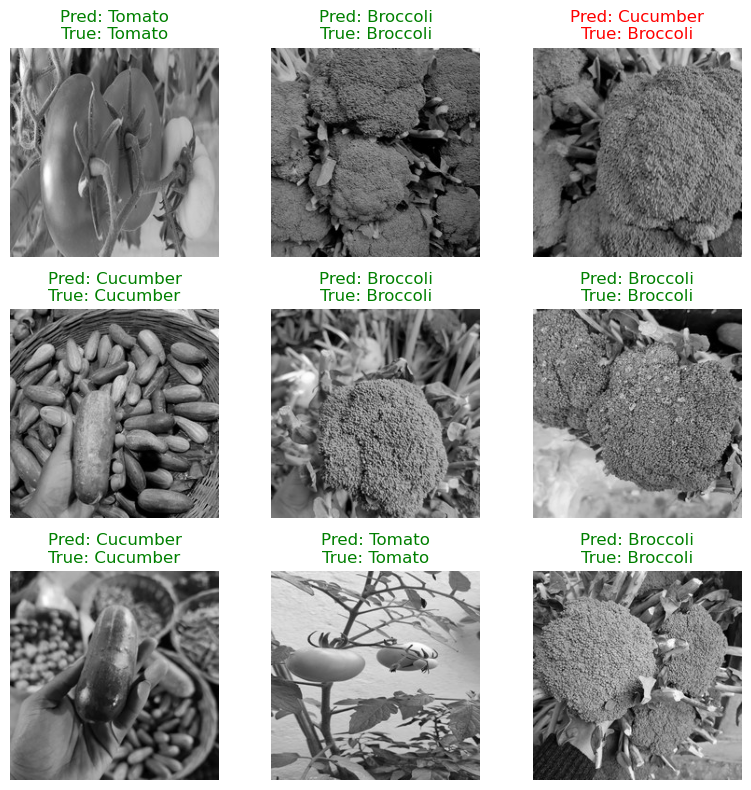

In [13]:
#PREDICT DATA
prediction = model.predict(x_test)                  #probability masuk ke tiap kelas
predicted_class = np.argmax(prediction, axis=1)     #ambil kelas dengan probability tertinggi
true_class = np.argmax(y_test, axis=1)              #one-hot -> index kelas asli

#PRINT LOSS & ACCURACY (dihitung manual dari hasil prediksi)
test_accuracy = np.mean(predicted_class == true_class)
test_loss = np.mean(keras.losses.categorical_crossentropy(y_test, prediction))
print(f"Test Accuracy : {test_accuracy}")
print(f"Test Loss     : {test_loss}")

#TAMPILKAN 9 GAMBAR TEST PERTAMA + HASIL PREDIKSI
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")    #squeeze: (224, 224, 1) -> (224, 224)
    color = "green" if predicted_class[i] == true_class[i] else "red"
    plt.title(f"Pred: {CLASS_NAMES[predicted_class[i]]}\nTrue: {CLASS_NAMES[true_class[i]]}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Model Evaluation
`evaluate` menghitung loss & accuracy langsung dari model. Angkanya harus sama dengan hasil manual di Predict Data.

In [14]:
#MODEL EVALUATION
eval_loss, eval_accuracy = model.evaluate(x_test, y_test)
print(f"Test Accuracy : {eval_accuracy}")
print(f"Test Loss     : {eval_loss}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8400 - loss: 0.7656
Test Accuracy : 0.8399999737739563
Test Loss     : 0.7656049132347107


## Plot Evaluation Metrics

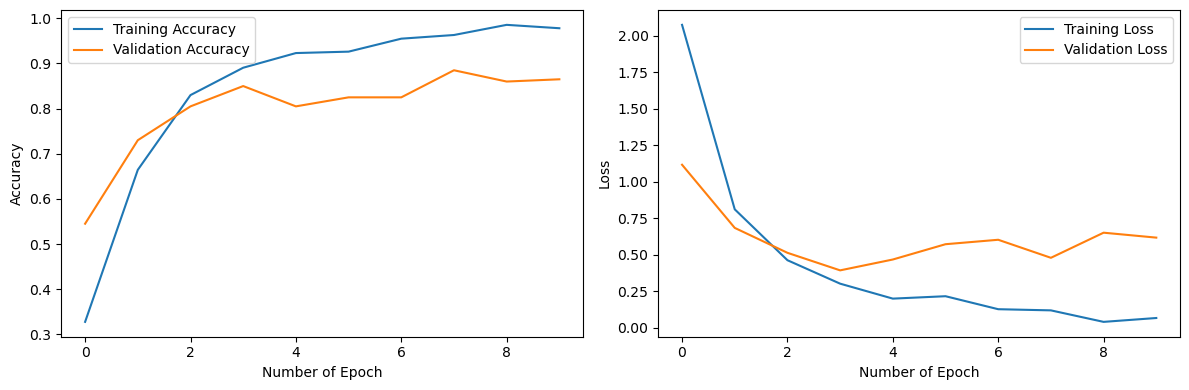

In [ ]:
#PLOT EVALUATION METRICS
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Number of Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Number of Epoch')
plt.ylabel('Loss (%)')
plt.legend()

plt.tight_layout()
plt.show()